# 03 Polynomial Regression (degree 2)
เส้นตรงโค้งไม่ได้ เลยเพิ่ม x² และ xi × xj เข้าไป
ใช้ 5 feature (`fico, revol.util, dti, inq.last.6mths, credit.policy`) ขยายเป็น 5 + 5 + 10 = 20 คอลัมน์ เทรนด้วย gradient descent (lr 0.05, 3,000 รอบ)

โค้ด: `Model/Regression/PolynomialRegression.py`  
ผลลัพธ์: `Results/Regression/03_Polynomial_Regression/`

## 1. เตรียมข้อมูล

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Model", "Common")))

from project import Outputs, regression_data
from model_zoo import RegressionPipeline, check_settings
from report_regression import report_regressor
from PolynomialRegression import PolynomialRegressionScratch
from model_zoo import POLY_FEATURES
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

out = Outputs("Regression", "03_Polynomial_Regression")
d = regression_data()
print(f"train {d.X_train.shape} | test {d.X_test.shape} | target int.rate | {len(d.feature_cols)} features")

train (7662, 20) | test (1916, 20) | target int.rate | 20 features


## 2. เทรนโมเดล

In [2]:
print("polynomial inputs:", POLY_FEATURES)
model = RegressionPipeline(
    PolynomialRegressionScratch(degree=2, learning_rate=0.05, n_iterations=3000), columns=POLY_FEATURES
)
check_settings("3. Polynomial (deg 2)", model)
model.fit(d.X_train, d.y_train, d.feature_cols)

pf = PolynomialFeatures(2, include_bias=False)
sk = LinearRegression().fit(pf.fit_transform(model.transform(d.X_train)), d.y_train)
sk_r2 = sk.score(pf.transform(model.transform(d.X_test)), d.y_test)

polynomial inputs: ['fico', 'revol.util', 'dti', 'inq.last.6mths', 'credit.policy']
settings match Common/model_zoo.py (7 values checked)


## 3. ผลลัพธ์

Train loss (MSE)    0.000308
Test loss (MSE)     0.000282
Test RMSE           0.016779
Test MAE            0.012667
Test R2             0.591023
scikit-learn R2     0.591023
Difference         -0.000000

scratch vs scikit-learn PolynomialFeatures + LinearRegression: R2 0.5910 vs 0.5910 (difference -0.0000)


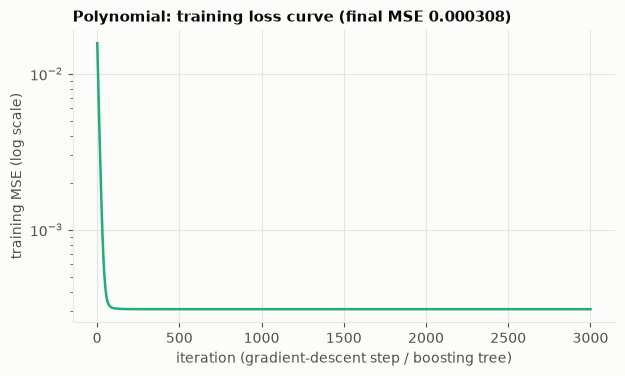

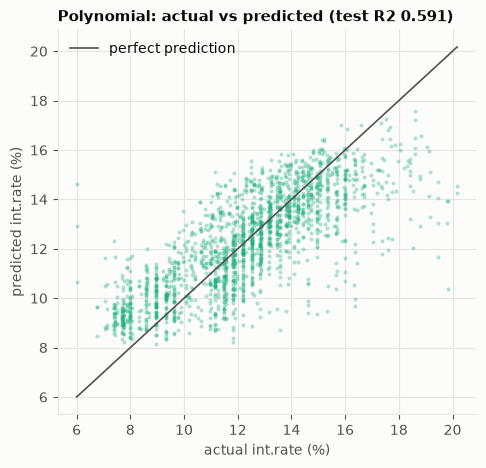

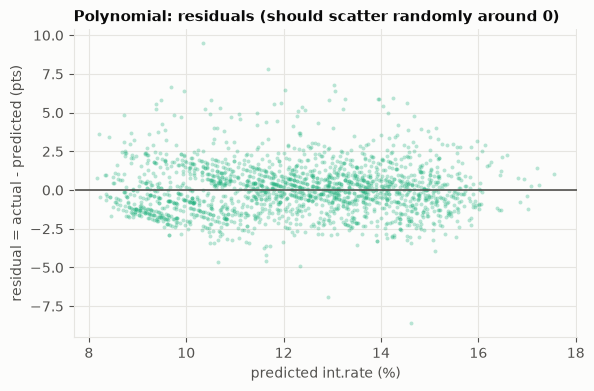

saved + reloaded Results/Regression/03_Polynomial_Regression/model.joblib (identical predictions: True)


In [3]:
row = report_regressor(
    out,
    "3. Polynomial (deg 2)",
    model,
    d,
    model.model.loss_history,
    (sk_r2, "scikit-learn PolynomialFeatures + LinearRegression"),
)